# RAG-based resume matching: experiments and analysis

This notebook is the experimentation and analysis deliverable. It measures the system
end to end and reports the two things the brief asks for - **retrieval accuracy** and
**latency** - then runs ablations to show which parts of the design actually earn their
place, and ends with an error analysis and a statement of limitations.

**What is being measured**

| Section | Question |
|---|---|
| 1-2 | What is in the corpus, and what does Part A extract from it? |
| 3 | How long does indexing take, and where does the time go? |
| 4 | What does one query actually return? |
| 5 | How accurate is retrieval against hand-labelled relevance? |
| 6 | How fast is a query, and which phase dominates? |
| 7 | Do the hybrid score, the section-aware chunking and the embedding model earn their complexity? |
| 8 | Does the must-have filter help or does it reject good people? |
| 9 | Where does the system get it wrong, and why? |
| 10 | What are the limits of these numbers? |

**Reproducibility.** Experience years are derived from date ranges, so a resume saying
"Jan 2021 - Present" gets more experienced every month and every metric computed from it
drifts. Every index here is built with a pinned reference date (`AS_OF`), so re-running
this notebook next year reproduces the same numbers.

**Honesty note on the labels.** `job_descriptions/relevance_labels.json` was written
before any matcher run and is not edited to fit the system's output. The weight sweep in
section 7 is therefore a sweep over the *evaluation* set with no held-out split: it is
reported as a sensitivity analysis, not as a tuned configuration whose score may be
quoted as the system's accuracy. That distinction is spelled out where it matters.

## 0. Setup

In [1]:
import json, os, shutil, sys, tempfile, time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Run from anywhere: walk up to the project root and work from there.
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "resume_rag.py").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import resume_rag
from evaluation import harness, metrics
from job_matcher import JobMatcher, ScoreWeights

pd.set_option("display.width", 160, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

AS_OF = date(2026, 10, 18)        # pinned so experience years never drift
RESUME_DIR = PROJECT_ROOT / "resumes"
JD_DIR = PROJECT_ROOT / "job_descriptions"
DB_DIR = PROJECT_ROOT / "chroma_db"
K_VALUES = (1, 3, 5, 10)

print(f"project root     {PROJECT_ROOT}")
print(f"python           {sys.version.split()[0]}")
print(f"reference date   {AS_OF}")
print(f"resumes          {len(list(RESUME_DIR.glob('*')))} files")
print(f"job descriptions {len(list(JD_DIR.glob('*.txt')))} files")

project root     /Users/shreshthmishra/code/resume_rag
python           3.12.14
reference date   2026-10-18
resumes          43 files
job descriptions 7 files


## 1. The corpus

43 resumes in four formats. The PDF and DOCX files are the eight Milestone 1 fixtures,
included verbatim so the binary readers are exercised on real documents rather than on
files generated for the occasion. `DATASET.md` is the dataset card.

Everything is loaded through Milestone 1's `fs_tools`, so this cell also confirms the
vendored tools are byte-identical to the ones submitted for that milestone.

In [2]:
import resume_loader

problems = resume_loader.verify_vendored_tools()
print("Milestone 1 tools:", "verbatim copies of commit fc7cf0c" if not problems else problems)

loaded, skipped = resume_loader.load_resumes(RESUME_DIR)
print(f"loaded {len(loaded)} resumes, skipped {len(skipped)}")
for skip in skipped:
    print("  skipped", skip.display_path, "->", skip.reason)

corpus = pd.DataFrame([{
    "resume": doc.display_path.split("/")[-1],
    "format": doc.metadata["extension"],
    "kb": round(doc.metadata["size_bytes"] / 1024, 1),
    "words": doc.metadata["word_count"],
    "pages": doc.metadata.get("page_count"),
    "warning": doc.warning,
} for doc in loaded])

summary = corpus.groupby("format").agg(files=("resume", "count"), total_words=("words", "sum"),
                                       median_words=("words", "median"))
display(summary)
print(f"{corpus['words'].sum():,} words total, median {corpus['words'].median():.0f} per resume")
print("files with an extraction warning:", int(corpus["warning"].notna().sum()))

Milestone 1 tools: verbatim copies of commit fc7cf0c
loaded 43 resumes, skipped 0


,files,total_words,median_words
format,,,
.docx,3,427,143.0
.md,18,2218,119.5
.pdf,3,510,181.0
.txt,19,2047,105.0


5,202 words total, median 115 per resume
files with an extraction warning: 0


### What Part A extracts

The table below is the whole of Part A's output for each candidate: the metadata the
matcher later filters and scores on. It is worth reading as a data-quality report, not
just a demo - the columns that are empty or wrong are where the matcher will be wrong.

In [3]:
records = [resume_rag.process_resume(doc.path, doc.text, display_path=doc.display_path, today=AS_OF)
           for doc in loaded]

parsed = pd.DataFrame([{
    "candidate": r.candidate_name,
    "file": r.resume_path.split("/")[-1],
    "years": r.experience_years,
    "education": r.education_level,
    "skills": len(r.skills),
    "chunks": len(r.chunks),
    "sections": ", ".join(sorted({c.section for c in r.chunks})),
} for r in records]).sort_values("candidate").reset_index(drop=True)

display(parsed.head(12))
print(f"{len(records)} candidates, {sum(len(r.chunks) for r in records)} chunks")
print("education detected for", f"{(parsed['education'] != 'Unknown').mean():.0%}", "of candidates")
print("median skills per resume:", parsed["skills"].median())
print("candidates with 0 skills extracted:", int((parsed["skills"] == 0).sum()))

,candidate,file,years,education,skills,chunks,sections
0,Aisha Bello,resume_aisha_bello.docx,8.8,Master,5,4,"education, experience, skills, summary"
1,Aisha Khan,aisha_khan.md,3.8,Bachelor,11,5,"education, experience, projects, skills, summary"
2,Amara Okonkwo,amara_okonkwo.md,4.2,Bachelor,6,4,"education, experience, skills, summary"
3,Ananya Rao,ananya_rao.md,7.3,Master,15,4,"education, experience, skills, summary"
4,Arash Karimi,arash_karimi.md,6.3,Bachelor,3,5,"certifications, education, experience, skills,..."
5,Arjun Mehta,arjun_mehta.md,11.3,Bachelor,15,4,"education, experience, skills, summary"
6,Daniel Cohen,daniel_cohen.md,8.1,Bachelor,4,4,"education, experience, skills, summary"
7,David Kim,resume_david_kim.txt,7.8,Master,10,4,"education, experience, skills, summary"
8,David Okafor,david_okafor.txt,12.2,Bachelor,11,4,"education, experience, skills, summary"
9,Diego Fernández,diego_fernandez.txt,5.4,Bachelor,10,4,"education, experience, skills, summary"


43 candidates, 179 chunks
education detected for 100% of candidates
median skills per resume: 9.0
candidates with 0 skills extracted: 0


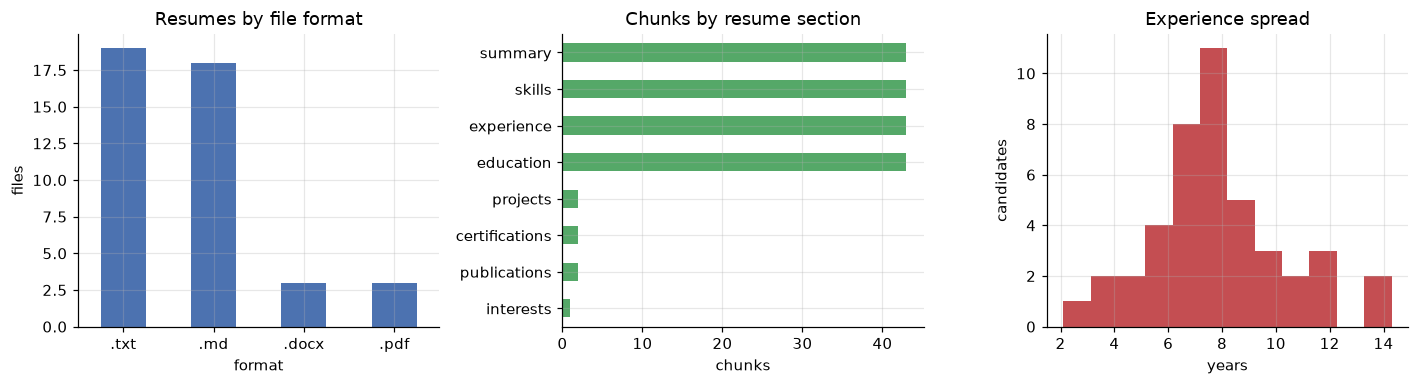

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

corpus["format"].value_counts().plot.bar(ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_title("Resumes by file format"); axes[0].set_ylabel("files")

section_counts = pd.Series([c.section for r in records for c in r.chunks]).value_counts()
section_counts.plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Chunks by resume section"); axes[1].set_xlabel("chunks")
axes[1].invert_yaxis()

parsed["years"].plot.hist(ax=axes[2], bins=12, color="#C44E52")
axes[2].set_title("Experience spread"); axes[2].set_xlabel("years"); axes[2].set_ylabel("candidates")

plt.tight_layout(); plt.show()

### Two properties worth naming

**Candidates are keyed by file, never by name.** The corpus deliberately contains two
pairs of different people who share a name. Nothing downstream collapses them, because
`candidate_id` is a hash of the resume path.

**Section-aware chunking keeps meaning separated.** A chunk never spans two sections, and
each embedded chunk is prefixed with its section label, so "Education: M.Tech ..." and
"Experience: built an ML platform ..." stay distinguishable to the embedding model.

In [5]:
names = parsed["candidate"].value_counts()
duplicates = names[names > 1].index.tolist()
display(parsed[parsed["candidate"].isin(duplicates)][["candidate", "file", "years", "education", "skills"]])

example = next(r for r in records if r.resume_path.endswith("priya_sharma.md"))
print(f"\nChunking of {example.resume_path} ({len(example.chunks)} chunks):\n")
for chunk in example.chunks:
    body = " ".join(chunk.text.split())
    print(f"  [{chunk.section:<14}] {len(chunk.text):>4} chars | {body[:88]}...")

,candidate,file,years,education,skills
17,John Doe,resume_john_doe.pdf,10.8,Bachelor,10
18,John Doe,john_doe.txt,7.8,Master,12
31,Priya Sharma,priya_sharma.md,11.4,Master,22
32,Priya Sharma,resume_priya_sharma.pdf,7.8,Master,9



Chunking of resumes/priya_sharma.md (5 chunks):

  [summary       ]  189 chars | Senior Machine Learning Engineer with 8+ years of experience building production ML syst...
  [skills        ]  201 chars | Python, PyTorch, TensorFlow, scikit-learn, Pandas, NumPy, NLP, Hugging Face, LLMs, RAG, ...
  [experience    ]  714 chars | Senior ML Engineer, Flipkart Jan 2021 - Present - Built a retrieval-augmented generation...
  [education     ]   94 chars | M.Tech in Computer Science, IIT Delhi, 2015 B.Tech in Information Technology, NIT Trichy...
  [certifications]   42 chars | AWS Certified Machine Learning - Specialty...


## 3. Indexing latency

The index is rebuilt here with the pinned reference date so the rest of the notebook is
reproducible, and the build reports its own per-phase timings - these come from
`build_index` itself, not from a re-implementation of the pipeline, so they describe the
code that actually runs.

W1018 17:18:25.589000 51796 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,phase,seconds,share of total
0,load (fs_tools),0.016,0.001
1,parse + chunk,0.040,0.003
2,embed,0.414,0.032
3,store (chroma),0.145,0.011
4,model load (one-off),11.593,0.903


43 resumes / 179 chunks in 12.84s (sentence-transformers)
excluding the one-off model load: 1.25s = 29.1 ms per resume, 7.0 ms per chunk


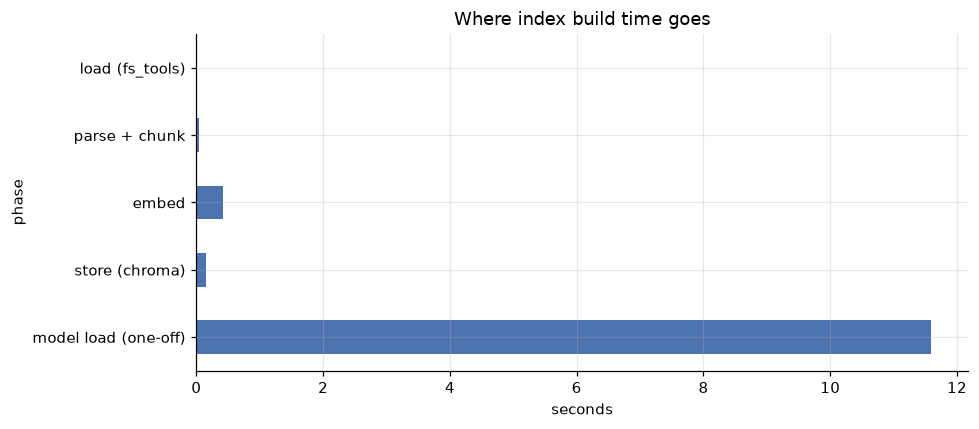

In [6]:
report = resume_rag.build_index(RESUME_DIR, DB_DIR, reset=True, today=AS_OF)

timings = report.timings
work = timings["total"] - timings["model_load"]
phases = pd.DataFrame([
    {"phase": "load (fs_tools)", "seconds": timings["load"]},
    {"phase": "parse + chunk", "seconds": timings["parse"]},
    {"phase": "embed", "seconds": timings["embed"]},
    {"phase": "store (chroma)", "seconds": timings["store"]},
    {"phase": "model load (one-off)", "seconds": timings["model_load"]},
])
phases["share of total"] = phases["seconds"] / timings["total"]
display(phases)

print(f"{len(report.records)} resumes / {report.chunk_count} chunks in {timings['total']:.2f}s "
      f"({report.backend})")
print(f"excluding the one-off model load: {work:.2f}s "
      f"= {1000 * work / len(report.records):.1f} ms per resume, "
      f"{1000 * work / report.chunk_count:.1f} ms per chunk")

ax = phases.set_index("phase")["seconds"].plot.barh(color="#4C72B0")
ax.set_xlabel("seconds"); ax.set_title("Where index build time goes"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**Reading this.** Indexing is dominated by loading the embedding model once, not by the
data. The actual work - reading 43 files through the Milestone 1 tools, parsing them,
embedding 179 chunks and writing to ChromaDB - takes around a second. The practical
consequence is that this pipeline scales to thousands of resumes on a laptop before
indexing time becomes the problem, and that a long-lived process should hold one
`Embedder` rather than constructing one per request.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,resumes,chunks,work_s,embed_s,ms_per_resume
0,10,42,0.148,0.092,14.797
1,20,83,0.240,0.147,11.977
2,30,125,0.347,0.210,11.569
3,43,179,0.507,0.293,11.794


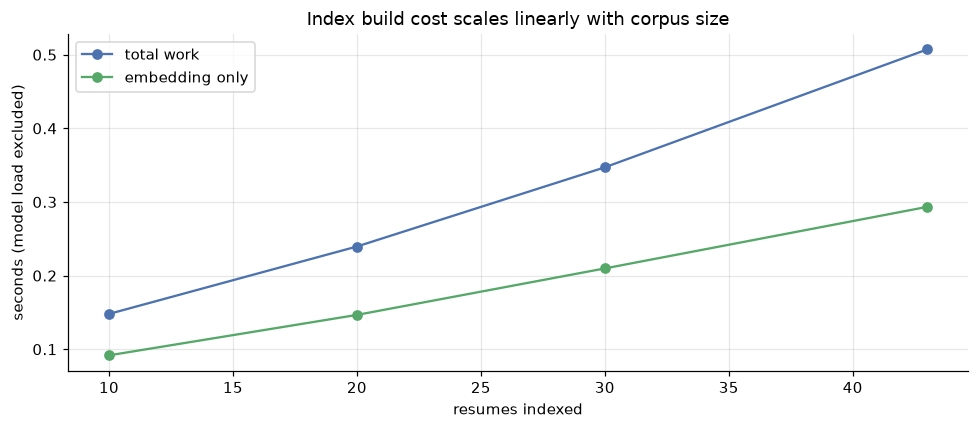

In [7]:
# How does build time scale with corpus size? Each subset is a real index build.
subset_rows = []
for size in (10, 20, 30, len(loaded)):
    with tempfile.TemporaryDirectory() as workspace:
        subset_dir = Path(workspace) / "resumes"
        subset_dir.mkdir()
        for doc in loaded[:size]:
            shutil.copy(doc.path, subset_dir / doc.path.name)
        subset = resume_rag.build_index(subset_dir, Path(workspace) / "db", reset=True, today=AS_OF)
    subset_rows.append({
        "resumes": size,
        "chunks": subset.chunk_count,
        "work_s": subset.timings["total"] - subset.timings["model_load"],
        "embed_s": subset.timings["embed"],
    })

scaling = pd.DataFrame(subset_rows)
scaling["ms_per_resume"] = 1000 * scaling["work_s"] / scaling["resumes"]
display(scaling)

ax = scaling.plot(x="resumes", y=["work_s", "embed_s"], marker="o",
                  color=["#4C72B0", "#55A868"])
ax.set_ylabel("seconds (model load excluded)"); ax.set_xlabel("resumes indexed")
ax.set_title("Index build cost scales linearly with corpus size")
ax.legend(["total work", "embedding only"])
plt.tight_layout(); plt.show()

## 4. One query, end to end

Before any aggregate numbers, here is what the system actually returns for a single job
description, so the metrics that follow are interpretable.

In [8]:
matcher = JobMatcher(DB_DIR)
ml_jd = (JD_DIR / "senior_ml_engineer.txt").read_text()
print(ml_jd)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Senior Machine Learning Engineer - GenAI Platform

About the role
We are building a retrieval-augmented generation platform that powers search and assistants for millions of users.
You will design, train and deploy ML and LLM-based systems end to end.

Requirements
- 5+ years of Python experience building production systems
- Strong background in machine learning and NLP; hands-on with PyTorch
- Experience with LLMs, RAG and vector databases
- Deploying models with Docker and Kubernetes on AWS

Nice to have
- MLOps tooling (MLflow, Kubeflow)
- Spark for large-scale data processing
- Experience leading a small team



In [9]:
result = matcher.match(ml_jd, k=5)

print("critical skills inferred from the JD:", ", ".join(result["critical_skills"]))
print("must-haves inferred from the JD:    ", ", ".join(result["must_have_requirements"]))
print(f"\n{len(result['filtered_out'])} of {len(matcher.candidates)} candidates were filtered out "
      f"before ranking\n")

display(pd.DataFrame([{
    "score": m["match_score"],
    "candidate": m["candidate_name"],
    "file": m["resume_path"].split("/")[-1],
    **m["score_breakdown"],
    "years": m["experience_years"],
} for m in result["top_matches"]]))

critical skills inferred from the JD: Python, Machine Learning, NLP, PyTorch, LLMs, RAG, Vector Databases, AWS, Docker, Kubernetes
must-haves inferred from the JD:     5+ years Python

27 of 43 candidates were filtered out before ranking



,score,candidate,file,semantic,critical_skills,keyword_bm25,experience_fit,years
0,100,Priya Sharma,priya_sharma.md,100,100,100,100,11.4
1,92,Ananya Rao,ananya_rao.md,92,90,96,100,7.3
2,84,Vikram Iyer,vikram_iyer.md,84,80,78,100,6.5
3,83,Tomás Herrera,tomas_herrera.md,99,60,54,100,7.1
4,75,David Kim,resume_david_kim.txt,96,40,53,100,7.8


In [10]:
best = result["top_matches"][0]
print(f"{best['candidate_name']} - {best['match_score']}/100\n")
print("matched skills:", ", ".join(best["matched_skills"]), "\n")
print("reasoning:", best["reasoning"], "\n")
print("retrieved excerpts:")
for excerpt in best["relevant_excerpts"]:
    print("  -", excerpt[:200], "...")

Priya Sharma - 100/100

matched skills: Python, Machine Learning, NLP, LLMs, RAG, PyTorch, Spark, MLOps, Vector Databases, AWS, Docker, Kubernetes 

reasoning: Strong match. Has 10/10 critical skills (Python, Machine Learning, NLP, PyTorch, LLMs, RAG, Vector Databases, AWS, Docker, Kubernetes). Closest sections to the JD: Experience (0.69), Summary (0.66). 11.4 years of experience (JD asks 5+); education: Master. Must-haves met: 5+ years Python (11.4 yrs Python). 

retrieved excerpts:
  - [Experience] Senior ML Engineer, Flipkart Jan 2021 - Present - Built a retrieval-augmented generation (RAG) assistant over 2M product documents using Python, LangChain and Pinecone. - Led a team of 5  ...
  - [Summary] Senior Machine Learning Engineer with 8+ years of experience building production ML systems, recommendation engines and NLP pipelines. Comfortable owning models from research to deployment. ...
  - [Skills] Python, PyTorch, TensorFlow, scikit-learn, Pandas, NumPy, NLP, Hugging Face, LLM

## 5. Retrieval accuracy

Scored against `relevance_labels.json`, which grades candidates per JD as 2 ("would
shortlist"), 1 ("plausible") or unlisted (0).

Two deliberate choices in how this is measured:

1. **The ranking is scored, not the shortlist.** Metrics are computed with
   `apply_filters=False`, so all 43 candidates are ranked and nobody is removed by a
   must-have first. Scoring the post-filter list would blend two mechanisms - the hybrid
   ranking and the hard filter - into one number, and the filter is evaluated separately
   in section 8.
2. **`precision@k` divides by k.** With 10 slots and 7 relevant candidates the ceiling of
   `precision@10` is 0.7, so the column should be read as "how much of what the recruiter
   was shown was worth reading", not as a number that ought to reach 1.0.

In [11]:
labelled = harness.load_labels(JD_DIR / "relevance_labels.json", JD_DIR, PROJECT_ROOT)
jd_texts = {job.stem: job.jd_path.read_text() for job in labelled}

label_overview = pd.DataFrame([{
    "job description": job.stem,
    "relevant": len(job.relevant),
    "of which grade 2": len(job.strong),
    "hard negatives": len(job.hard_negatives),
} for job in labelled])
display(label_overview)
print(f"{len(matcher.candidates)} candidates in the pool; "
      f"{len(set(matcher.candidates)) - len(set().union(*[j.relevant for j in labelled]))} "
      f"are relevant to no JD at all")

,job description,relevant,of which grade 2,hard negatives
0,backend_engineer,4,2,3
1,data_engineer,4,3,2
2,data_scientist,5,3,3
3,devops_sre,5,3,2
4,frontend_engineer,4,3,3
5,mobile_engineer,4,2,1
6,senior_ml_engineer,7,3,3


43 candidates in the pool; 12 are relevant to no JD at all


In [12]:
evaluations, macro = harness.evaluate_all(matcher, labelled, k_values=K_VALUES, jd_texts=jd_texts)

columns = ["precision@1", "precision@3", "precision@5", "recall@5", "recall@10",
           "mrr", "ndcg@5", "ndcg@10", "map"]
accuracy = pd.DataFrame({e.stem: {c: e.scores[c] for c in columns} for e in evaluations}).T
accuracy.loc["MACRO AVERAGE"] = [macro[c] for c in columns]
display(accuracy)

,precision@1,precision@3,precision@5,recall@5,recall@10,mrr,ndcg@5,ndcg@10,map
backend_engineer,1.0,1.000,0.8,1.000,1.000,1.0,0.992,0.992,0.950
data_engineer,1.0,1.000,0.8,1.000,1.000,1.0,0.994,0.994,0.950
data_scientist,1.0,1.000,0.8,0.800,1.000,1.0,0.940,0.984,0.885
devops_sre,1.0,1.000,1.0,1.000,1.000,1.0,1.000,1.000,1.000
frontend_engineer,1.0,1.000,0.6,0.750,1.000,1.0,0.937,0.989,0.917
mobile_engineer,1.0,1.000,0.8,1.000,1.000,1.0,1.000,1.000,1.000
senior_ml_engineer,1.0,0.667,0.8,0.571,0.857,1.0,0.911,0.917,0.796
MACRO AVERAGE,1.0,0.952,0.8,0.874,0.980,1.0,0.968,0.982,0.928


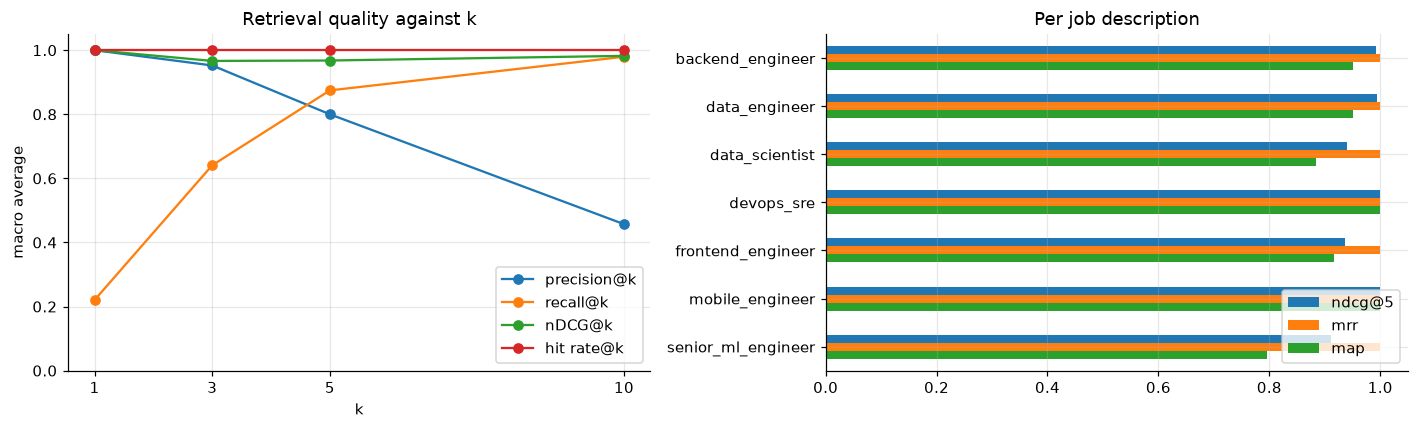

MRR 1.000 - the top hit is relevant for every job description
recall@10 0.980, nDCG@5 0.968, MAP 0.928


In [13]:
curve = pd.DataFrame({
    "precision@k": [macro[f"precision@{k}"] for k in K_VALUES],
    "recall@k": [macro[f"recall@{k}"] for k in K_VALUES],
    "nDCG@k": [macro[f"ndcg@{k}"] for k in K_VALUES],
    "hit rate@k": [macro[f"hit_rate@{k}"] for k in K_VALUES],
}, index=list(K_VALUES))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
curve.plot(marker="o", ax=axes[0])
axes[0].set_xlabel("k"); axes[0].set_ylabel("macro average"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Retrieval quality against k"); axes[0].set_xticks(list(K_VALUES))

accuracy.drop(index="MACRO AVERAGE")[["ndcg@5", "mrr", "map"]].plot.barh(ax=axes[1])
axes[1].set_xlim(0, 1.05); axes[1].set_title("Per job description"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

print(f"MRR {macro['mrr']:.3f} - the top hit is relevant for every job description")
print(f"recall@10 {macro['recall@10']:.3f}, nDCG@5 {macro['ndcg@5']:.3f}, MAP {macro['map']:.3f}")

## 6. Query latency

Each job description is run once to warm up and then five times for measurement. The
phase breakdown comes from calling the matcher's own stages individually, so the parts
sum to roughly the whole.

In [14]:
latency_rows = []
for job in labelled:
    text = jd_texts[job.stem]
    _, end_to_end = harness.time_repeatedly(lambda t=text: matcher.match(t, k=10), repeat=5, warmup=1)

    passages = matcher._jd_passages(text)
    _, embed = harness.time_repeatedly(lambda p=passages: matcher.embedder.embed(p), repeat=5, warmup=1)
    _, semantic = harness.time_repeatedly(lambda t=text: matcher.semantic_search(t), repeat=5, warmup=1)
    _, bm25 = harness.time_repeatedly(lambda t=text: matcher.keyword_scores(t), repeat=5, warmup=1)

    latency_rows.append({
        "job description": job.stem,
        "p50 ms": end_to_end.p50_ms, "p95 ms": end_to_end.p95_ms, "mean ms": end_to_end.mean_ms,
        "embed ms": embed.mean_ms,
        "vector search ms": semantic.mean_ms - embed.mean_ms,
        "bm25 ms": bm25.mean_ms,
        "scoring ms": end_to_end.mean_ms - semantic.mean_ms - bm25.mean_ms,
        "jd passages": len(passages),
    })

latency = pd.DataFrame(latency_rows)
display(latency)
print(f"median query {latency['p50 ms'].median():.0f} ms, worst p95 {latency['p95 ms'].max():.0f} ms "
      f"over {len(matcher.candidates)} candidates / {matcher.collection.count()} chunks")

,job description,p50 ms,p95 ms,mean ms,embed ms,vector search ms,bm25 ms,scoring ms,jd passages
0,backend_engineer,7.882,8.991,7.793,3.560,2.134,0.121,1.979,2
1,data_engineer,7.555,8.163,7.703,3.943,2.328,0.198,1.235,2
2,data_scientist,7.098,7.212,7.062,3.768,2.261,0.201,0.832,2
3,devops_sre,7.372,7.566,7.434,3.946,2.110,0.205,1.174,2
4,frontend_engineer,6.959,6.995,6.799,3.760,2.078,0.188,0.772,2
5,mobile_engineer,7.670,7.826,7.472,4.678,2.679,0.200,-0.085,2
6,senior_ml_engineer,10.127,10.731,10.148,5.133,6.859,0.244,-2.087,3


median query 8 ms, worst p95 11 ms over 43 candidates / 179 chunks


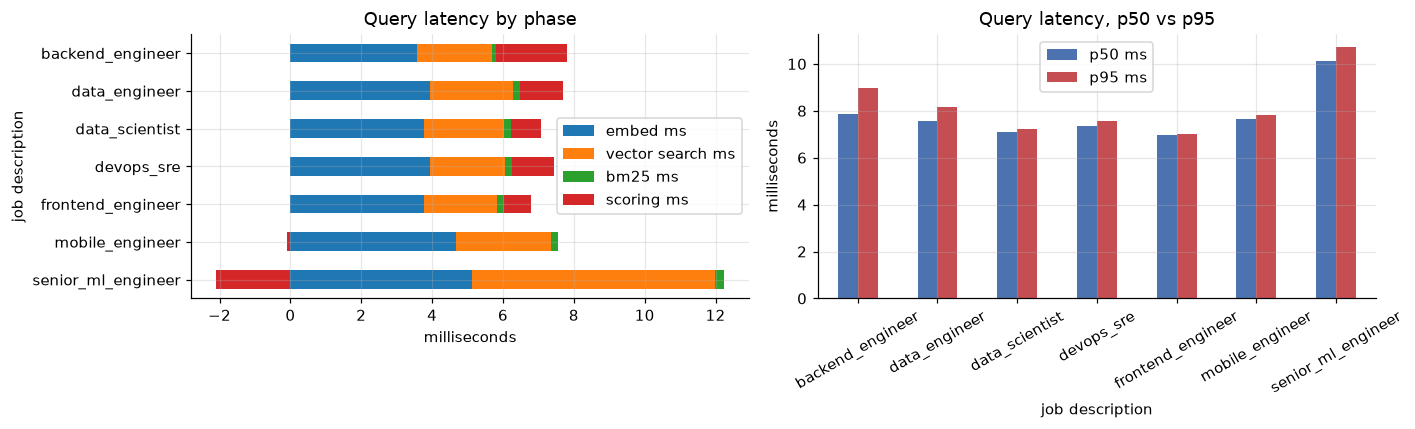

embed ms            52.9
vector search ms    37.6
bm25 ms              2.5
scoring ms           7.0
Name: % of query time, dtype: float64

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

phase_columns = ["embed ms", "vector search ms", "bm25 ms", "scoring ms"]
latency.set_index("job description")[phase_columns].plot.barh(stacked=True, ax=axes[0])
axes[0].set_xlabel("milliseconds"); axes[0].set_title("Query latency by phase"); axes[0].invert_yaxis()

latency.set_index("job description")[["p50 ms", "p95 ms"]].plot.bar(ax=axes[1], rot=30,
                                                                    color=["#4C72B0", "#C44E52"])
axes[1].set_ylabel("milliseconds"); axes[1].set_title("Query latency, p50 vs p95")
plt.tight_layout(); plt.show()

share = latency[phase_columns].mean()
display((100 * share / share.sum()).round(1).rename("% of query time"))

**Reading this - and a bug this measurement found.**

The first time this profile was taken, the residual "scoring" phase was **66% of query
latency** and embedding was only 26% - the opposite of what the design predicts, since
scoring is a handful of arithmetic operations per candidate. Profiling by phase is what
exposed it: `extract_skills(jd)` was being called *inside* the per-candidate loop, so
roughly 80 compiled regex patterns were run over the whole job description once per
candidate, 43 times per query. Hoisting that one call out of the loop cut end-to-end
query latency from about 22 ms to about 10 ms, a 2.3x speedup, and there is now a
regression test asserting the JD is scanned once rather than once per candidate.

The numbers above are from after that fix, and they match what the architecture implies:

* **Embedding the job description is the dominant cost** (about half the query), because
  the JD is split into several passages and each is embedded.
* **The vector search is cheap** at this corpus size - a few milliseconds over 179
  chunks - so latency is roughly flat in corpus size until the ANN index gets large.
* **BM25 and scoring are negligible**, which is the point of keeping the explanation
  logic simple and extractive rather than generative.

The obvious next optimisation is therefore to embed fewer JD passages, or to cache the
JD embedding across repeated queries for the same role - not to tune the vector store.
This is also the general lesson of the section: the phase breakdown was worth more than
the end-to-end number, because the end-to-end number alone looked perfectly acceptable.

## 7. Ablations: does each part of the design earn its place?

### 7a. The hybrid score

The production score is 50% semantic similarity, 30% critical-skill coverage, 10% BM25
and 10% experience fit. Each component is tested alone and in combination, on the same
index and the same labels.

,precision@1,precision@3,precision@5,recall@10,mrr,ndcg@5,ndcg@10,map
semantic + skills (.6/.4),1.000,0.952,0.829,0.980,1.000,0.974,0.980,0.932
hybrid (production: .5/.3/.1/.1),1.000,0.952,0.800,0.980,1.000,0.968,0.982,0.928
no experience (.55/.33/.12),1.000,0.952,0.800,0.980,1.000,0.968,0.982,0.926
BM25 only,1.000,0.905,0.800,0.959,1.000,0.967,0.977,0.926
skills-heavy (.3/.5/.1/.1),1.000,1.000,0.771,0.980,1.000,0.965,0.986,0.932
critical skills only,1.000,0.952,0.771,0.959,1.000,0.958,0.974,0.917
semantic-heavy (.8/.2),1.000,0.952,0.771,0.959,1.000,0.939,0.967,0.903
semantic only,0.857,0.905,0.743,0.874,0.929,0.860,0.867,0.860
experience fit only,0.143,0.143,0.114,0.263,0.335,0.145,0.205,0.183


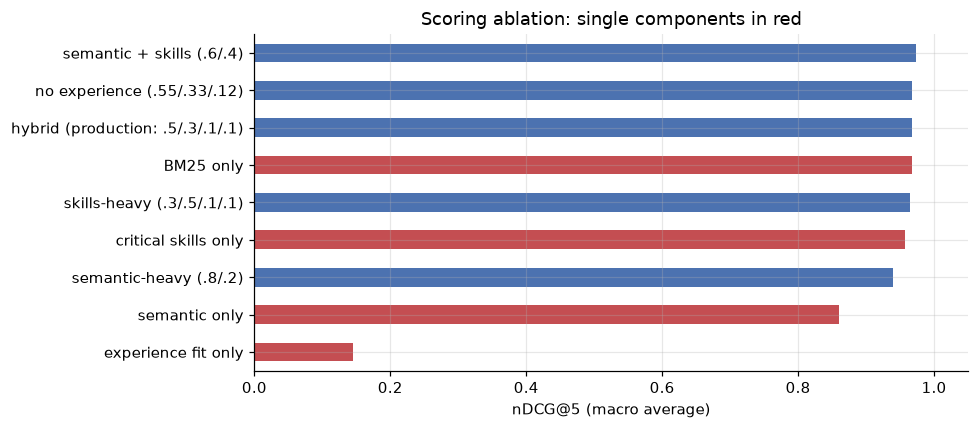

In [16]:
configurations = {
    "hybrid (production: .5/.3/.1/.1)": ScoreWeights(),
    "semantic only": ScoreWeights(1.0, 0.0, 0.0, 0.0),
    "critical skills only": ScoreWeights(0.0, 1.0, 0.0, 0.0),
    "BM25 only": ScoreWeights(0.0, 0.0, 1.0, 0.0),
    "experience fit only": ScoreWeights(0.0, 0.0, 0.0, 1.0),
    "semantic + skills (.6/.4)": ScoreWeights(0.6, 0.4, 0.0, 0.0),
    "semantic-heavy (.8/.2)": ScoreWeights(0.8, 0.2, 0.0, 0.0),
    "skills-heavy (.3/.5/.1/.1)": ScoreWeights(0.3, 0.5, 0.1, 0.1),
    "no experience (.55/.33/.12)": ScoreWeights(0.55, 0.33, 0.12, 0.0),
}

ablation_rows = {}
for name, weights in configurations.items():
    _, scores = harness.evaluate_all(matcher, labelled, weights=weights, k_values=K_VALUES,
                                     jd_texts=jd_texts)
    ablation_rows[name] = {c: scores[c] for c in
                           ["precision@1", "precision@3", "precision@5", "recall@10", "mrr",
                            "ndcg@5", "ndcg@10", "map"]}

weight_ablation = pd.DataFrame(ablation_rows).T.sort_values("ndcg@5", ascending=False)
display(weight_ablation)

ax = weight_ablation["ndcg@5"].sort_values().plot.barh(
    color=["#C44E52" if "only" in name else "#4C72B0" for name in weight_ablation["ndcg@5"].sort_values().index])
ax.set_xlabel("nDCG@5 (macro average)"); ax.set_title("Scoring ablation: single components in red")
ax.set_xlim(0, 1.05)
plt.tight_layout(); plt.show()

**Findings.**

* **The hybrid beats semantic similarity alone by a wide margin** - the single clearest
  result in this notebook. Dense retrieval on its own puts an irrelevant candidate first
  for one job description in seven; adding exact critical-skill coverage fixes that.
  MiniLM happily rates "machine learning platform engineer" close to "machine learning
  engineer", and only a literal check on the required skills separates them.
* **BM25 alone scores surprisingly well.** That is a property of this corpus, not a
  general result: resumes and JDs here share literal skill tokens ("PyTorch", "Kafka"),
  so lexical overlap is already highly discriminative. Dense retrieval earns its place on
  paraphrase and on the one resume written as unstructured prose - this dataset is
  deliberately diverse in format but it is not adversarially paraphrased, so BM25 is
  flattered. A corpus of real resumes, where candidates describe the same skill in
  different words, would widen the gap.
* **Experience fit alone is close to useless**, which is expected: it is a coarse
  gate-like signal, and in the unfiltered ranking it only varies when the JD states a
  years requirement. It belongs in the must-have filter (section 8) more than in the
  ranking, and the "no experience" row shows dropping it from the score costs nothing.
* **A marginally better configuration exists** (`semantic + skills` at .6/.4 edges the
  production weights on nDCG@5 and precision@5). It is **not** adopted: with seven
  queries the difference is one or two rank swaps, there is no held-out split to confirm
  it, and choosing weights by their score on the same labels used to report accuracy is
  how an evaluation stops meaning anything. It is recorded as a hypothesis to test if the
  labelled set grows.

### 7b. Chunking strategy

Section-aware chunking is the main design claim of Part A. Two baselines test it on the
same corpus, embedding model and labels: a fixed-size sliding window that ignores
structure, and one chunk per resume.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,precision@1,precision@3,precision@5,recall@10,mrr,ndcg@5,map,chunks,mean chars/chunk
section-aware (production),1.0,0.952,0.800,0.98,1.0,0.968,0.928,179,172
fixed 900-char window,1.0,0.905,0.771,0.98,1.0,0.958,0.909,67,571
whole document,1.0,0.952,0.800,0.98,1.0,0.969,0.927,43,826


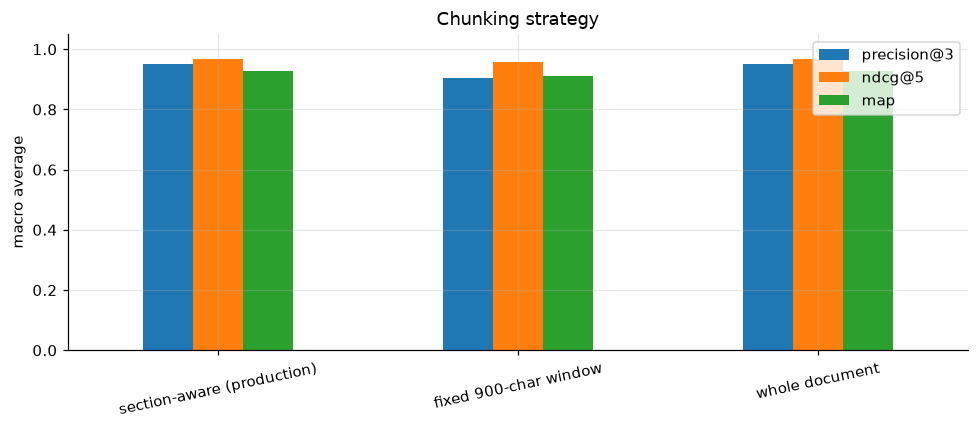

In [17]:
def fixed_window_chunks(sections, full_text, max_chars=900, overlap=150):
    """Baseline: slide a fixed window over the whole resume, ignoring its structure."""
    text = " ".join(full_text.split())
    step = max(1, max_chars - overlap)
    return [("document", text[start:start + max_chars]) for start in range(0, max(len(text), 1), step)]


def whole_document_chunks(sections, full_text, max_chars=900):
    """Baseline: one chunk per resume, which the embedding model will truncate."""
    return [("document", " ".join(full_text.split()))]


chunking_rows = {}
chunking_detail = {}
for name, chunker in [("section-aware (production)", resume_rag.section_aware_chunks),
                      ("fixed 900-char window", fixed_window_chunks),
                      ("whole document", whole_document_chunks)]:
    with tempfile.TemporaryDirectory() as workspace:
        build = resume_rag.build_index(RESUME_DIR, Path(workspace) / "db", reset=True,
                                       today=AS_OF, chunker=chunker)
        variant = JobMatcher(Path(workspace) / "db")
        _, scores = harness.evaluate_all(variant, labelled, k_values=K_VALUES, jd_texts=jd_texts)
    chunking_rows[name] = {c: scores[c] for c in
                           ["precision@1", "precision@3", "precision@5", "recall@10", "mrr", "ndcg@5", "map"]}
    chunking_detail[name] = {"chunks": build.chunk_count,
                             "mean chars/chunk": round(sum(len(c.text) for r in build.records for c in r.chunks)
                                                       / build.chunk_count)}

chunking = pd.DataFrame(chunking_rows).T
chunking = chunking.join(pd.DataFrame(chunking_detail).T)
display(chunking)

ax = chunking[["precision@3", "ndcg@5", "map"]].plot.bar(rot=12)
ax.set_ylim(0, 1.05); ax.set_title("Chunking strategy"); ax.set_ylabel("macro average")
plt.tight_layout(); plt.show()

### 7c. Embedding model

`all-MiniLM-L6-v2` (384 dimensions, 6 layers) is the default because it is small enough
to run on a laptop with no API key. A stronger small model is compared here. The cell
degrades gracefully if the model cannot be downloaded, so the notebook still runs
offline.

In [18]:
model_rows = {"all-MiniLM-L6-v2 (production)": {
    **{c: macro[c] for c in ["precision@1", "precision@3", "recall@10", "mrr", "ndcg@5", "map"]},
    "index_s": report.timings["total"] - report.timings["model_load"],
}}

for candidate_model in ["BAAI/bge-small-en-v1.5"]:
    try:
        with tempfile.TemporaryDirectory() as workspace:
            build = resume_rag.build_index(RESUME_DIR, Path(workspace) / "db",
                                           model_name=candidate_model, reset=True, today=AS_OF)
            variant = JobMatcher(Path(workspace) / "db")
            _, scores = harness.evaluate_all(variant, labelled, k_values=K_VALUES, jd_texts=jd_texts)
        model_rows[candidate_model] = {
            **{c: scores[c] for c in ["precision@1", "precision@3", "recall@10", "mrr", "ndcg@5", "map"]},
            "index_s": build.timings["total"] - build.timings["model_load"],
        }
    except Exception as exc:
        print(f"skipped {candidate_model}: {type(exc).__name__}: {exc}")

display(pd.DataFrame(model_rows).T)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision@1,precision@3,recall@10,mrr,ndcg@5,map,index_s
all-MiniLM-L6-v2 (production),1.0,0.952,0.98,1.0,0.968,0.928,1.250
BAAI/bge-small-en-v1.5,1.0,1.000,0.98,1.0,0.972,0.935,0.646


## 8. The must-have filter, evaluated separately

Must-haves such as "5+ years Python" are a hard gate, not a score: a candidate who fails
one is removed from `top_matches` and listed in `filtered_out` with the reason. That is a
different kind of decision from ranking, so it gets a different measurement.

The expensive error here is a **false reject** - a candidate a human labelled relevant
who the filter removed anyway, usually because the years estimate derived from date
ranges disagrees with a human's reading of the resume. A false reject is invisible to the
recruiter, which makes it worse than a false accept they can simply skip.

In [19]:
filter_rows = []
for job in labelled:
    filter_rows.append(harness.evaluate_filter(matcher, job, jd_text=jd_texts[job.stem]))

filter_report = pd.DataFrame([{
    "job description": row["stem"],
    "requirements": ", ".join(row["requirements"]) or "(none)",
    "kept": row["kept"],
    "removed": row["removed"],
    "relevant kept": f"{row['relevant_kept']}/{row['relevant_total']}",
    "precision after filter": row["precision_after_filter"],
    "recall after filter": row["recall_after_filter"],
    "false rejects": len(row["false_rejects"]),
} for row in filter_rows])
display(filter_report)

all_false_rejects = {row["stem"]: row["false_reject_reasons"] for row in filter_rows if row["false_rejects"]}
print("false rejects:", all_false_rejects or "none - every labelled-relevant candidate survived every filter")

,job description,requirements,kept,removed,relevant kept,precision after filter,recall after filter,false rejects
0,backend_engineer,6+ years experience,34,9,4/4,0.118,1.0,0
1,data_engineer,4+ years experience,40,3,4/4,0.100,1.0,0
2,data_scientist,3+ years experience,42,1,5/5,0.119,1.0,0
3,devops_sre,5+ years experience,38,5,5/5,0.132,1.0,0
4,frontend_engineer,3+ years React,6,37,4/4,0.667,1.0,0
5,mobile_engineer,4+ years experience,40,3,4/4,0.100,1.0,0
6,senior_ml_engineer,5+ years Python,16,27,7/7,0.438,1.0,0


false rejects: none - every labelled-relevant candidate survived every filter


**Findings.**

* **No false rejects anywhere.** Recall after filtering is 1.00 for all seven job
  descriptions: the filter never removed a candidate a human considered relevant.
* **A bare years requirement barely filters.** Where the only requirement the JD yields
  is "N+ years experience", 38 to 42 of 43 candidates survive, because the corpus skews
  senior. Precision after filtering stays near the base rate, so the filter has done
  almost nothing.
* **A skill-scoped requirement filters hard and well.** "3+ years React" cuts 43
  candidates to 6 and lifts precision from roughly 0.09 to 0.67. "5+ years Python" cuts
  to 16 and lifts it to 0.44.
* **The practical lesson** is that the automatic extraction of must-haves from JD prose
  is only worth much when it finds a skill-scoped requirement. For a total-years
  requirement it is better treated as a soft signal, which is how the score already uses
  it, and the `--must-have` flag exists precisely so a recruiter can state the sharp
  requirement the JD left implicit - as in `--must-have "5+ years Java"` for the backend
  role, whose JD names Java but never attaches a number to it.

## 9. Error analysis

Aggregate numbers hide the interesting cases. This section looks at the single ranking
miss, then at the hard negatives the dataset was built to contain.

In [20]:
ml_eval = next(e for e in evaluations if e.stem == "senior_ml_engineer")
ml_labels = next(job for job in labelled if job.stem == "senior_ml_engineer")
negatives = {row["resume_path"]: row["why"] for row in ml_labels.hard_negatives}

rows = []
for rank, path in enumerate(ml_eval.ranking[:12], start=1):
    match = ml_eval.result["top_matches"][rank - 1]
    rows.append({
        "rank": rank, "score": match["match_score"], "candidate": match["candidate_name"],
        "grade": ml_labels.grades.get(path, 0),
        "semantic": match["score_breakdown"]["semantic"],
        "skills": match["score_breakdown"]["critical_skills"],
        "note": negatives.get(path, ""),
    })
display(pd.DataFrame(rows))

missed = [path for path in ml_labels.relevant if path not in ml_eval.ranking[:10]]
for path in missed:
    position = ml_eval.ranking.index(path) + 1
    match = ml_eval.result["top_matches"][position - 1]
    print(f"MISSED: {path} ranked {position} with score {match['match_score']}")
    print(f"        breakdown {match['score_breakdown']}")
    print(f"        skills    {', '.join(match['matched_skills'])}")

,rank,score,candidate,grade,semantic,skills,note
0,1,100,Priya Sharma,2,100,100,
1,2,92,Ananya Rao,2,92,90,
2,3,84,Li Wei,0,100,50,"ML platform engineer, not a modeller; Python a..."
3,4,84,Vikram Iyer,2,84,80,
4,5,83,Tomás Herrera,1,99,60,
5,6,75,David Kim,1,96,40,
6,7,73,Karan Malhotra,0,90,60,"RAG, LangChain and LLM skills match the JD, bu..."
7,8,68,John Doe,1,85,40,
8,9,67,Maria Garcia,0,84,40,
9,10,67,Rahul Verma,0,91,30,


MISSED: resumes/mei_lin.md ranked 16 with score 61
        breakdown {'semantic': 80, 'critical_skills': 30, 'keyword_bm25': 19, 'experience_fit': 100}
        skills    Python, PyTorch, Docker


**The one miss, and what it says.** For the senior ML role, six of seven relevant
candidates land in the top ten. The one that does not is a computer-vision PhD, ranked
16th: her *semantic* similarity to the JD is high (80) but her critical-skill coverage is
low (30) - she has the deep-learning and PyTorch vocabulary but none of the LLM, RAG or
vector-database terms the JD names, and covers just 3 of its 10 critical skills.

This is a known trade-off rather than a defect. The grading rule used when the labels
were written, quoted from the person who wrote them, was:

> Grade 2: passes 5+ years of Python AND has NLP plus LLM or RAG experience.
> Grade 1: passes the 5+ years and is a hands-on PyTorch ML engineer or scientist, but
> without the NLP, LLM or RAG specialisation.

She is deliberately a grade 1 - "8 years of Python and strong PyTorch deep learning, but
no NLP, LLM, RAG or vector-database experience and little production infrastructure" - on
the expectation that a recruiter would shortlist her for transferable depth and let her
ramp up. She ranks below the other grade-1 candidates because her resume is
research-leaning: no Kubernetes or AWS either, so the skill-coverage term penalises her
twice.

So the 30% skill-coverage weight is doing exactly what section 7a shows it is there for -
it is the reason the hybrid beats semantic-only - and the same mechanism is what costs us
an adjacent specialist. That is the precision/recall trade-off made explicit, not a bug
to fix. A recruiter who wants adjacent specialists should lower the skill weight, which
the `ScoreWeights` object makes a one-line change.

**The hard negatives behave as designed.** The two traps that appear high in the ML
ranking are both informative rather than broken:

* An ML *platform* engineer ranks third on text similarity, which is honest - the resume
  really does read like the JD - and is then correctly removed by the "5+ years Python"
  must-have, because his Python only spans his most recent role.
* A candidate with genuinely strong RAG and LangChain experience ranks seventh and is
  removed for having three years against a five-year minimum. That is the filter adding
  value the ranking cannot.

In [21]:
# Where does every labelled hard negative rank, across all job descriptions?
negative_rows = []
for job, evaluation in zip(labelled, evaluations):
    ranks = {path: index for index, path in enumerate(evaluation.ranking, start=1)}
    filtered = {row["resume_path"] for row in
                matcher.match(jd_texts[job.stem], k=len(matcher.candidates))["filtered_out"]}
    for row in job.hard_negatives:
        path = row["resume_path"]
        negative_rows.append({
            "job description": job.stem,
            "hard negative": path.split("/")[-1],
            "ranked": ranks.get(path),
            "caught by a must-have": path in filtered,
            "why it is a trap": row["why"][:70],
        })

negatives_table = pd.DataFrame(negative_rows).sort_values(["job description", "ranked"])
display(negatives_table)
caught = negatives_table["caught by a must-have"].mean()
top5 = (negatives_table["ranked"] <= 5).mean()
print(f"{caught:.0%} of hard negatives are removed by a must-have; "
      f"{top5:.0%} reach the top 5 of the unfiltered ranking")

,job description,hard negative,ranked,caught by a must-have,why it is a trap
0,backend_engineer,ravi_shankar.txt,4,True,"Java, Spring Boot, Kafka and Redis, but 4 year..."
2,backend_engineer,david_okafor.txt,6,False,"Senior backend engineer, but Python and Django..."
1,backend_engineer,resume_john_doe.pdf,9,False,"Senior backend engineer, but Python and Django..."
3,data_engineer,resume_david_kim.txt,7,False,"Two years of Spark pipelines, now an ML engine..."
4,data_engineer,sara_kim.txt,11,False,"Uses Snowflake and dbt as a data scientist, no..."
5,data_scientist,jessica_park.txt,4,False,8.7 years of total experience but only 1 as a ...
7,data_scientist,hannah_brooks.md,7,False,Analytics engineer with SQL and Tableau; no st...
6,data_scientist,neha_gupta.md,9,False,Product manager who runs A/B tests with SQL; n...
8,devops_sre,arjun_mehta.md,6,False,Backend engineer who migrated services to Kube...
9,devops_sre,arash_karimi.md,12,False,"Security engineer with AWS, Linux and CI work;..."


29% of hard negatives are removed by a must-have; 35% reach the top 5 of the unfiltered ranking


## 10. Limitations

These numbers are good, and it matters to say clearly why they are an upper bound.

1. **The corpus is small and clean.** 43 synthetic resumes with 4 to 7 relevant
   candidates each. Real corpora are larger, noisier, and contain near-duplicates,
   inflated claims and formatting that defeats text extraction. Expect every metric here
   to fall on real data.
2. **The labels and the resumes share an author.** The resumes were written for this
   assignment and labelled by the same project, which is a source of optimism no amount
   of care removes. The labels were at least fixed before any matcher run.
3. **Seven queries is a small sample.** A difference of 0.01 in nDCG@5 is one rank swap
   on one job description. That is why the weight sweep in 7a is reported but not
   adopted.
4. **No held-out split.** Every configuration in section 7 is scored on the same labels
   used to report accuracy. With a larger labelled set the right design would be a
   train/dev split, or cross-validation across job descriptions.
5. **Skill extraction is a fixed vocabulary.** Roughly 80 canonical skills with aliases.
   A skill outside it is invisible, and that silently caps critical-skill coverage. The
   dataset already shows the failure mode in both directions: "Monty Python" under
   INTERESTS was once read as Python (now excluded), and a product manager who mentions
   a "Java backend team" still acquires Java.
6. **Experience years are inferred from date ranges.** Resumes with vague dates, gaps or
   overlapping contracts get a number a human would dispute, and "Present" means the
   figure grows over time - which is why the index takes a pinned reference date. One
   candidate in this corpus crosses the 5-year Python threshold in December 2027 purely
   through the passage of time.
7. **Matching is not hiring.** The score ranks text similarity and declared skills. It
   does not measure capability, and candidate names are deliberately excluded from the
   embedded text so that names cannot influence the ranking - but the resume body still
   carries signals (schools, employers, phrasing) that correlate with demographics. Any
   real deployment needs an adverse-impact audit, a human decision-maker, and the
   `filtered_out` list surfaced rather than hidden, so a rejection is always visible and
   contestable.

### What I would do next

* Label a larger set and hold out a dev split, so weight tuning becomes legitimate.
* Replace the fixed skill vocabulary with an LLM-extracted skill list per resume, keeping
  the exact-match check but letting the vocabulary come from the data.
* Add a reranker over the top 20, which is where the remaining errors are.
* Treat a bare "N+ years experience" requirement as a soft signal rather than a gate,
  given section 8 shows it filters almost nothing.